Dataset Shape: (569, 30)
Target Shape: (569,)

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ... 

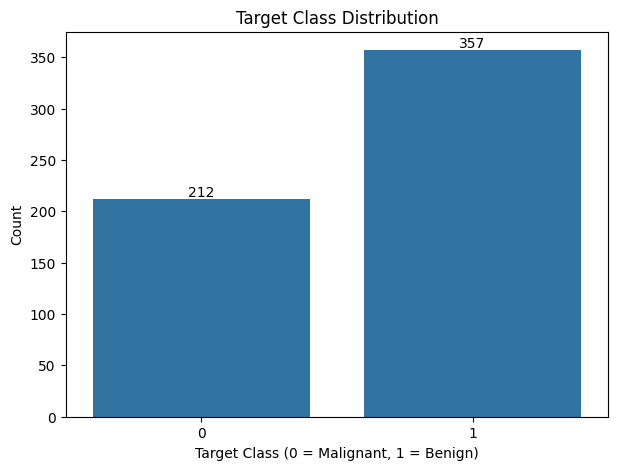

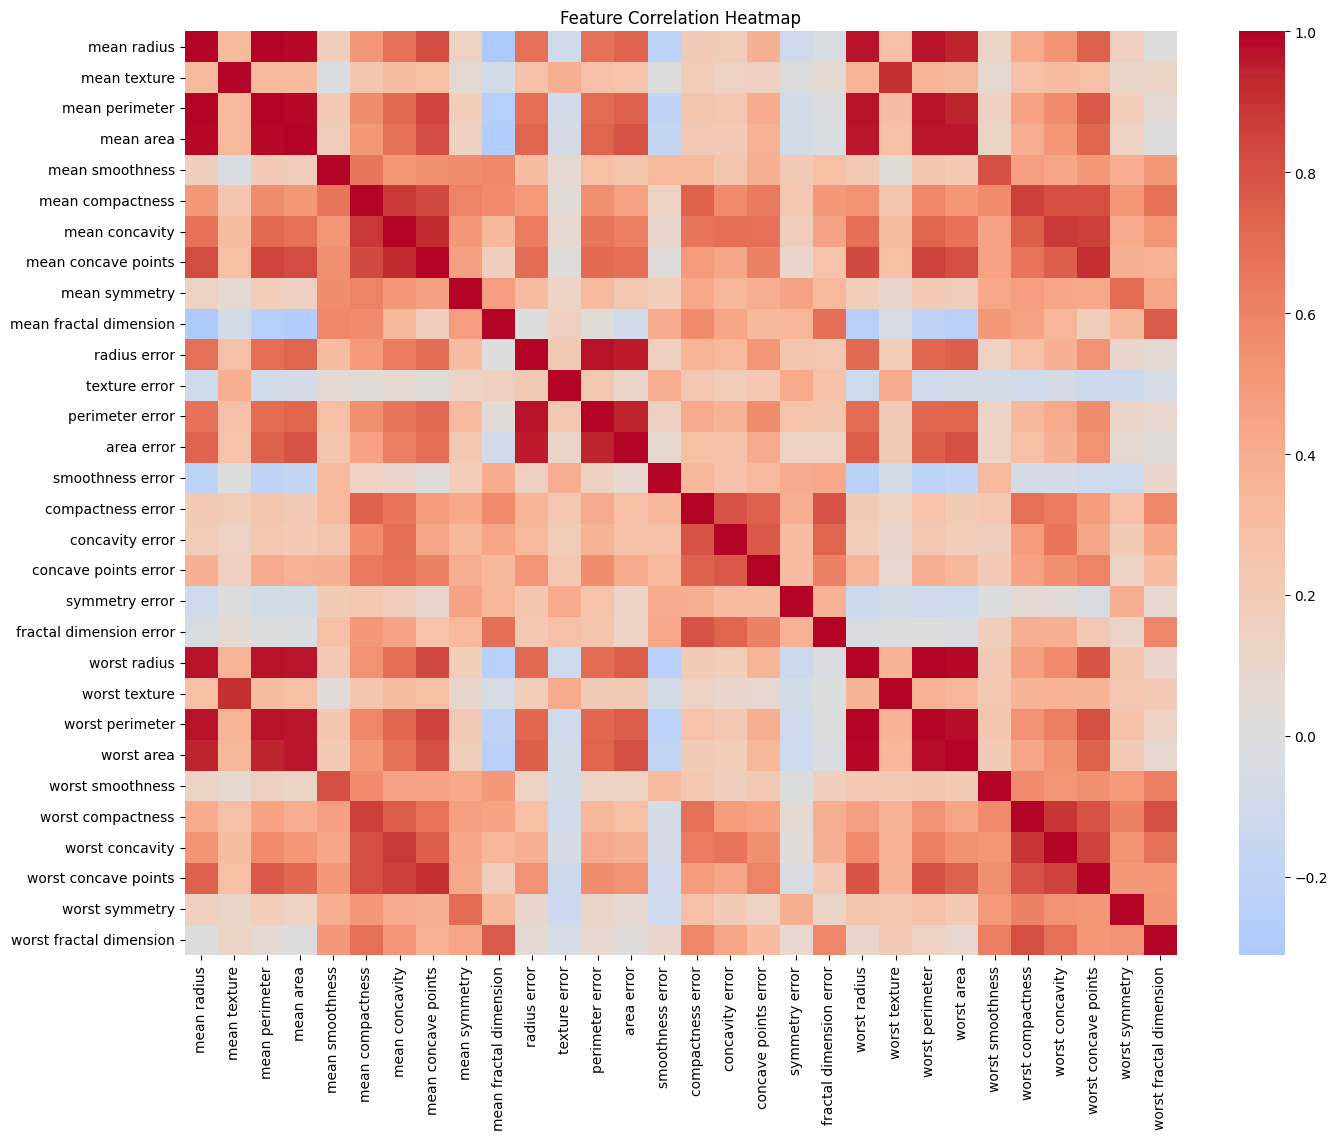

Top 10 Highly Correlated Feature Pairs:
mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
mean radius      worst radius       0.969539
mean perimeter   worst radius       0.969476
dtype: float64
X_train Shape: (455, 30)
X_test Shape: (114, 30)
y_train Shape: (455,)
y_test Shape: (114,)

Training Class Distribution:
target
0    170
1    285
Name: count, dtype: int64

Testing Class Distribution:
target
0    42
1    72
Name: count, dtype: int64
First 5 Rows of Scaled Training Data:
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
546    -1.072001     -0.658425       -1.088080  -0.939274        -0.135940   
432     1.748743      0.066502        1.751157   1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1.1 

# Load dataset
data = load_breast_cancer(as_frame=True)

# Convert into DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

X = data.data
y = data.target

# Display dataset information
print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFirst 5 Rows:")
print(X.head())

print("\nDataset Description:")
print(X.describe())

print("\nTarget Classes:")
print(data.target_names)

# 1.2 

plt.figure(figsize=(7, 5))

ax = sns.countplot(x=y)

ax.set_title("Target Class Distribution")
ax.set_xlabel("Target Class (0 = Malignant, 1 = Benign)")
ax.set_ylabel("Count")

# Add counts above bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        str(int(height)),
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.show()

# 1.3

# Calculate correlation matrix
corr = X.corr()

# Plot heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

# Find highly correlated feature pairs
corr_pairs = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack().sort_values(ascending=False)

print("Top 10 Highly Correlated Feature Pairs:")
print(corr_pairs.head(10))

# 1.4

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

# 1.5
# Create scaler
scaler = StandardScaler()

# Fit only on training data
scaler.fit(X_train)

# Transform training and testing data
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

# Convert scaled training data to DataFrame
X_train_sc = pd.DataFrame(
    X_train_sc,
    columns=X.columns,
    index=X_train.index
)

# Convert scaled testing data to DataFrame
X_test_sc = pd.DataFrame(
    X_test_sc,
    columns=X.columns,
    index=X_test.index
)

print("First 5 Rows of Scaled Training Data:")
print(X_train_sc.head())

print("\nTraining Data Mean (first 5 features):")
print(X_train_sc.mean().head())

print("\nTraining Data Standard Deviation (first 5 features):")
print(X_train_sc.std(ddof=0).head())

# 1.6

print("Original Dataset Shape:", X.shape)
print("Training Shape:", X_train_sc.shape)
print("Testing Shape:", X_test_sc.shape)

print("\nMissing Values in Dataset:", X.isnull().sum().sum())

print("\nScaled Training Mean (first 5 features):")
print(X_train_sc.mean().head())

print("\nScaled Training Standard Deviation (first 5 features):")
print(X_train_sc.std(ddof=0).head())

print("\nAll Task 1 steps completed successfully!")

SLP Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)


Total Trainable Parameters: 31
Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4914 - loss: 0.8156 - val_accuracy: 0.5870 - val_loss: 0.7237
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5697 - loss: 0.7300 - val_accuracy: 0.6739 - val_loss: 0.6554
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6504 - loss: 0.6542 - val_accuracy: 0.7174 - val_loss: 0.5984
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7066 - loss: 0.5910 - val_accuracy: 0.7609 - val_loss: 0.5506
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7628 - loss: 0.5394 - val_accuracy: 0.7609 - val_loss: 0.5104
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8044 - loss: 0.4940 - val_accuracy: 0.7826 - val_loss: 0.4772
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8240 - loss: 0.4574 - val_accuracy: 0.8478 - val_loss: 0.4494
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8509 - loss: 0

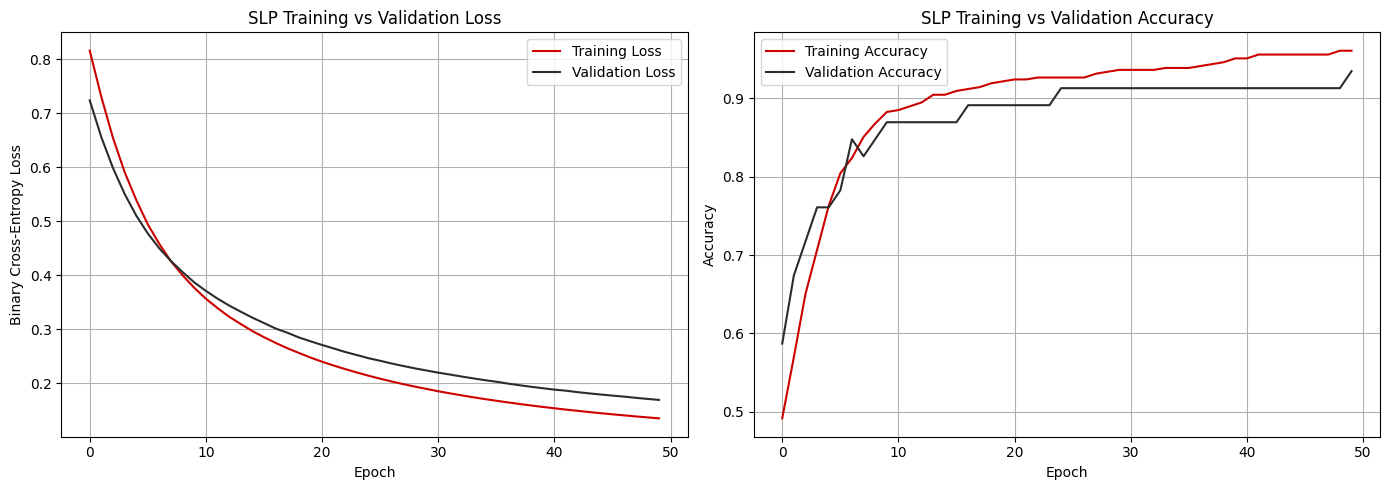


SLP Test Results
----------------
Test Loss: 0.1690
Test Accuracy: 0.9386
Test Accuracy (%): 93.86%

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.91      0.93      0.92        42
      Benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



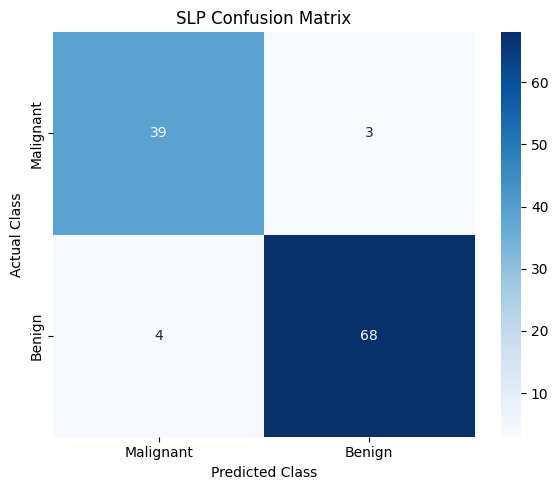


SLP Test Accuracy for Task 7: 93.86%

SLP LIMITATIONS
---------------
1. SLP has no hidden layers.
2. It learns a linear decision boundary.
3. It may not learn complex nonlinear patterns in the data.
4. Breast cancer classification may require more complex
   relationships between the 30 input features.
5. This baseline model will be compared with an MLP model
   in Task 3.


Task 2 completed successfully!


In [3]:
# ============================================================
# TASK 2: SINGLE-LAYER PERCEPTRON (SLP) - BASELINE MODEL
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 2.1 Build the SLP
# ------------------------------------------------------------

model_slp = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(1, activation="sigmoid")
])

print("SLP Model Summary:")
model_slp.summary()


# ------------------------------------------------------------
# 2.2 Compile the SLP
# ------------------------------------------------------------

model_slp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nTotal Trainable Parameters:",
      model_slp.count_params())

# Markdown explanation:
# Binary cross-entropy measures the difference between the
# predicted probability and the actual binary class label.
# It is suitable for binary classification with sigmoid output.
# MSE is commonly used for regression tasks.


# ------------------------------------------------------------
# 2.3 Train the SLP
# ------------------------------------------------------------

history_slp = model_slp.fit(
    X_train_sc,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------------------------
# 2.4 Plot SLP Training Curves
# ------------------------------------------------------------

plt.figure(figsize=(14, 5))

# Left plot: Training vs Validation Loss
plt.subplot(1, 2, 1)

plt.plot(
    history_slp.history["loss"],
    label="Training Loss",
    color="#CC0000"
)

plt.plot(
    history_slp.history["val_loss"],
    label="Validation Loss",
    color="#2C2C2C"
)

plt.title("SLP Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)

# Right plot: Training vs Validation Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    history_slp.history["accuracy"],
    label="Training Accuracy",
    color="#CC0000"
)

plt.plot(
    history_slp.history["val_accuracy"],
    label="Validation Accuracy",
    color="#2C2C2C"
)

plt.title("SLP Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2.5 Evaluate the SLP
# ------------------------------------------------------------

slp_loss, slp_acc = model_slp.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

print("\nSLP Test Results")
print("----------------")
print(f"Test Loss: {slp_loss:.4f}")
print(f"Test Accuracy: {slp_acc:.4f}")
print(f"Test Accuracy (%): {slp_acc * 100:.2f}%")


# Predict probabilities
y_pred_slp = model_slp.predict(
    X_test_sc,
    verbose=0
).ravel()

# Convert probabilities to class labels (0 or 1)
y_pred_slp = (y_pred_slp >= 0.5).astype(int)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_slp,
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)


# Confusion matrix
cm_slp = confusion_matrix(
    y_test,
    y_pred_slp,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_slp,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.title("SLP Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Save SLP accuracy for Task 7 comparison
# ------------------------------------------------------------

slp_test_accuracy = accuracy_score(
    y_test,
    y_pred_slp
)

print(
    f"\nSLP Test Accuracy for Task 7: "
    f"{slp_test_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# 2.6 SLP Limitations - Markdown Explanation
# ------------------------------------------------------------

print("""
SLP LIMITATIONS
---------------
1. SLP has no hidden layers.
2. It learns a linear decision boundary.
3. It may not learn complex nonlinear patterns in the data.
4. Breast cancer classification may require more complex
   relationships between the 30 input features.
5. This baseline model will be compared with an MLP model
   in Task 3.
""")

print("\nTask 2 completed successfully!")

MLP Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)


Manually Calculated Parameters: 4097
Model Parameters: 4097

WHY HIDDEN LAYERS?

1. Hidden layers learn useful patterns from input features.
2. Activation functions introduce non-linearity.
3. Multiple layers can learn more complex relationships.
4. A single hidden layer can theoretically approximate
   many continuous functions with sufficient neurons.
5. Deeper networks may learn hierarchical features.

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8191 - loss: 0.5265 - val_accuracy: 0.9348 - val_loss: 0.3822
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9584 - loss: 0.2873 - val_accuracy: 0.9130 - val_loss: 0.2637
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9609 - loss: 0.1837 - val_accuracy: 0.9130 - val_loss: 0.2030
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9682 - loss: 0.1350 - val_accuracy: 0.9348 - val_loss: 0.1597
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9731 - loss: 

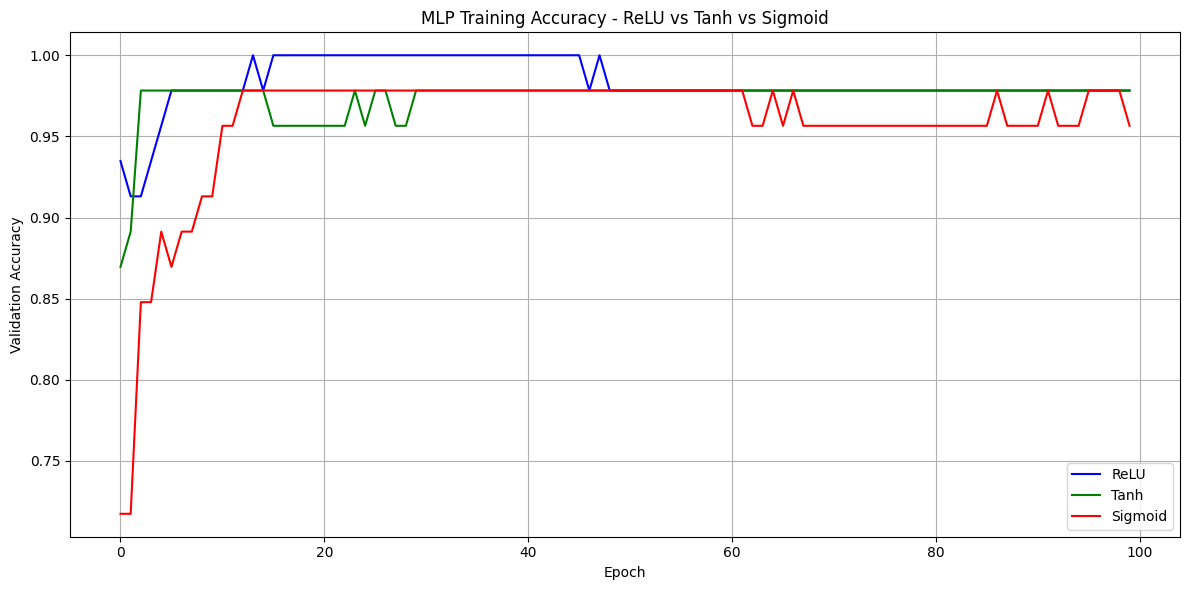


ACTIVATION FUNCTIONS:

1. ReLU:
   ReLU(x) = max(0, x)
   It is fast and commonly used in hidden layers.
   Negative inputs produce zero, which can sometimes
   cause dead neurons.

2. Tanh:
   Output range is -1 to 1.
   It is zero-centred but can suffer from vanishing gradients.

3. Sigmoid:
   Output range is 0 to 1.
   It can suffer from vanishing gradients in hidden layers.
   It is commonly used in the output layer for binary
   classification because it produces probabilities.

The best activation depends on the dataset and training results.


TEST ACCURACY COMPARISON
------------------------
ReLU Accuracy:    96.49%
Tanh Accuracy:    97.37%
Sigmoid Accuracy: 95.61%

Best Activation Based on Validation Accuracy: ReLU

Best MLP Classification Report:
              precision    recall  f1-score   support

   Malignant       0.93      0.98      0.95        42
      Benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg  

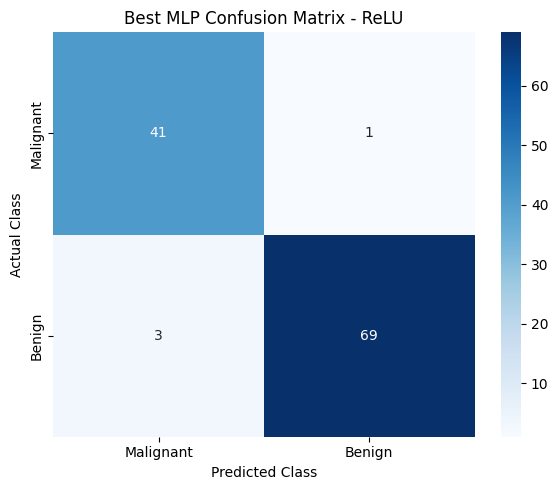


Best MLP Test Accuracy: 96.49%

Task 3 completed successfully!


In [4]:
# ============================================================
# TASK 3: MULTI-LAYER PERCEPTRON (MLP) - ACTIVATION FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# 3.1 Build the MLP (ReLU)
# ------------------------------------------------------------

model_mlp = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

print("MLP Model Summary:")
model_mlp.summary()

# Manually calculate parameters
total_parameters = (30 * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1)

print("\nManually Calculated Parameters:", total_parameters)
print("Model Parameters:", model_mlp.count_params())


# ------------------------------------------------------------
# 3.2 WHY Hidden Layers - Markdown Explanation
# ------------------------------------------------------------

print("""
WHY HIDDEN LAYERS?

1. Hidden layers learn useful patterns from input features.
2. Activation functions introduce non-linearity.
3. Multiple layers can learn more complex relationships.
4. A single hidden layer can theoretically approximate
   many continuous functions with sufficient neurons.
5. Deeper networks may learn hierarchical features.
""")


# ------------------------------------------------------------
# 3.3 Compile and Train MLP (ReLU)
# ------------------------------------------------------------

model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp = model_mlp.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------------------------
# 3.4 Compare Activation Functions
# ------------------------------------------------------------

# Model with Tanh activation
model_tanh = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(64, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(1, activation="sigmoid")
])

model_tanh.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_tanh = model_tanh.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# Model with Sigmoid activation in hidden layers
model_sigmoid = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(32, activation="sigmoid"),
    layers.Dense(1, activation="sigmoid")
])

model_sigmoid.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_sigmoid = model_sigmoid.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# Plot validation accuracy for all three models
plt.figure(figsize=(12, 6))

plt.plot(
    history_mlp.history["val_accuracy"],
    label="ReLU",
    color="blue"
)

plt.plot(
    history_tanh.history["val_accuracy"],
    label="Tanh",
    color="green"
)

plt.plot(
    history_sigmoid.history["val_accuracy"],
    label="Sigmoid",
    color="red"
)

plt.title("MLP Training Accuracy - ReLU vs Tanh vs Sigmoid")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.5 Activation Functions - Explanation
# ------------------------------------------------------------

print("""
ACTIVATION FUNCTIONS:

1. ReLU:
   ReLU(x) = max(0, x)
   It is fast and commonly used in hidden layers.
   Negative inputs produce zero, which can sometimes
   cause dead neurons.

2. Tanh:
   Output range is -1 to 1.
   It is zero-centred but can suffer from vanishing gradients.

3. Sigmoid:
   Output range is 0 to 1.
   It can suffer from vanishing gradients in hidden layers.
   It is commonly used in the output layer for binary
   classification because it produces probabilities.

The best activation depends on the dataset and training results.
""")


# ------------------------------------------------------------
# 3.6 Evaluate Best MLP
# ------------------------------------------------------------

# Evaluate each model on the test set
relu_loss, relu_acc = model_mlp.evaluate(
    X_test_sc, y_test, verbose=0
)

tanh_loss, tanh_acc = model_tanh.evaluate(
    X_test_sc, y_test, verbose=0
)

sigmoid_loss, sigmoid_acc = model_sigmoid.evaluate(
    X_test_sc, y_test, verbose=0
)

print("\nTEST ACCURACY COMPARISON")
print("------------------------")
print(f"ReLU Accuracy:    {relu_acc * 100:.2f}%")
print(f"Tanh Accuracy:    {tanh_acc * 100:.2f}%")
print(f"Sigmoid Accuracy: {sigmoid_acc * 100:.2f}%")


# Select best model based on validation accuracy
validation_scores = {
    "ReLU": max(history_mlp.history["val_accuracy"]),
    "Tanh": max(history_tanh.history["val_accuracy"]),
    "Sigmoid": max(history_sigmoid.history["val_accuracy"])
}

best_activation = max(validation_scores, key=validation_scores.get)

models = {
    "ReLU": model_mlp,
    "Tanh": model_tanh,
    "Sigmoid": model_sigmoid
}

best_model = models[best_activation]

print("\nBest Activation Based on Validation Accuracy:", best_activation)


# Predict using the selected model
y_prob_best = best_model.predict(X_test_sc, verbose=0).ravel()
y_pred_best = (y_prob_best >= 0.5).astype(int)

print("\nBest MLP Classification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Malignant", "Benign"],
    zero_division=0
))


# Confusion Matrix
cm_best = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.title(f"Best MLP Confusion Matrix - {best_activation}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# Store results for Task 7 comparison
mlp_test_accuracy = accuracy_score(y_test, y_pred_best)

print(f"\nBest MLP Test Accuracy: {mlp_test_accuracy * 100:.2f}%")
print("\nTask 3 completed successfully!")

MLP Model for Early Stopping:


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8851 - loss: 0.4062 - val_accuracy: 0.8913 - val_loss: 0.2803
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9584 - loss: 0.1674 - val_accuracy: 0.9348 - val_loss: 0.1830
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.1030 - val_accuracy: 0.9783 - val_loss: 0.1279
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9804 - loss: 0.0772 - val_accuracy: 0.9783 - val_loss: 0.0926
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9878 - loss: 0.0635 - val_accuracy: 0.9783 - val_loss: 0.0778
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9878 - loss: 0.0547 - val_accuracy: 0.9783 - val_loss: 0.0714
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9902 - loss: 0.0490 - val_accuracy: 0.9783 - val_loss: 0.0642
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9902 - loss: 0.0435 - val_accuracy: 0.97

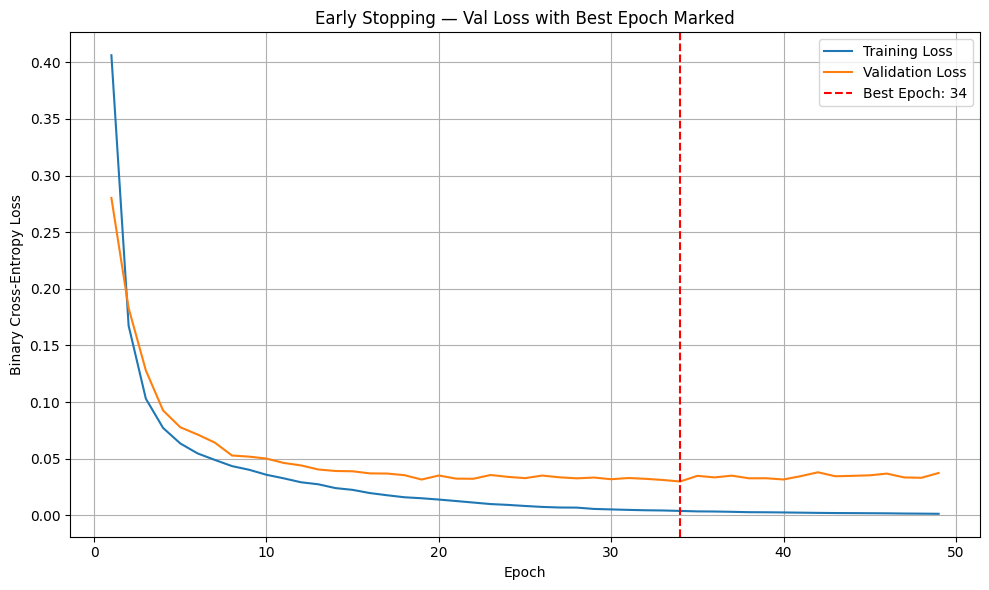

Best Epoch: 34
Last Epoch Trained: 49
Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8753 - loss: 0.4476 - val_accuracy: 0.8913 - val_loss: 0.3377
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9511 - loss: 0.1975 - val_accuracy: 0.9130 - val_loss: 0.2122
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9682 - loss: 0.1129 - val_accuracy: 0.9348 - val_loss: 0.1521
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9804 - loss: 0.0796 - val_accuracy: 0.9565 - val_loss: 0.1110
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9829 - loss: 0.0653 - val_accuracy: 0.9783 - val_loss: 0.0891
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.0573 - val_accuracy: 0.9783 - val_loss: 0.0792
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9878 - loss: 0.0511 - val_accuracy: 0.9783 - val_loss: 0.0728
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.98

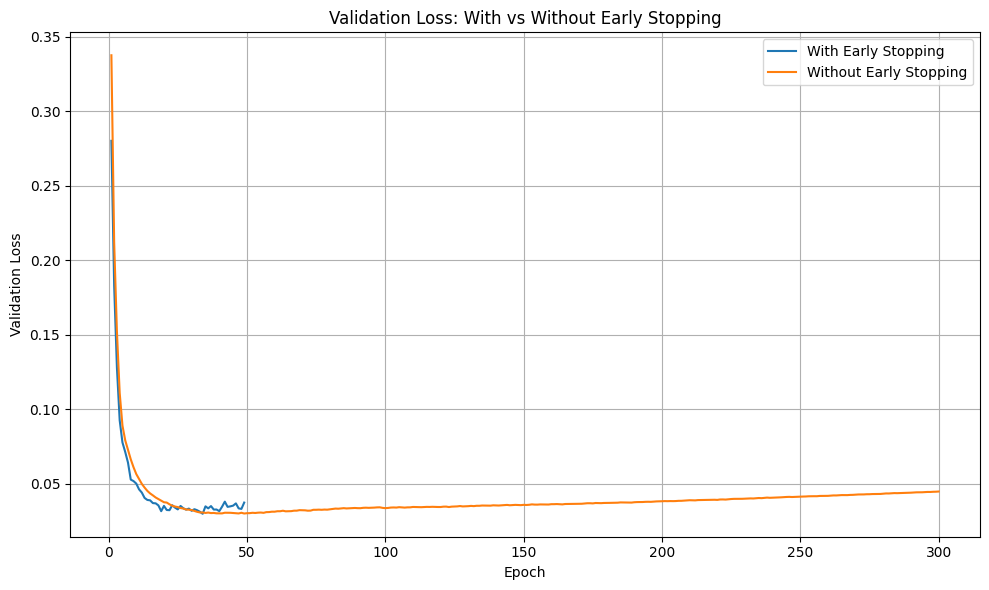


TEST SET COMPARISON
-------------------
Early Stopping Test Loss: 0.1270
Early Stopping Test Accuracy: 95.61%

Without Early Stopping Test Loss: 0.2486
Without Early Stopping Test Accuracy: 97.37%

Classification Report - With Early Stopping
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Classification Report - Without Early Stopping
              precision    recall  f1-score   support

   Malignant       0.95      0.98      0.96        42
      Benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


Task 4 Completed Successfully!


In [5]:
# ============================================================
# TASK 4: EARLY STOPPING
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# 4.1 Build a fresh MLP for Early Stopping
# ------------------------------------------------------------

def build_mlp():
    model = keras.Sequential([
        keras.Input(shape=(30,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create a fresh model
model_es = build_mlp()

print("MLP Model for Early Stopping:")
model_es.summary()


# ------------------------------------------------------------
# 4.2 Add Early Stopping Callback
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# Train with Early Stopping
history_es = model_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

print("\nActual Epochs Trained:", len(history_es.history["loss"]))
print("Best Validation Loss:", min(history_es.history["val_loss"]))


# ------------------------------------------------------------
# 4.3 WHY Early Stopping - Explanation
# ------------------------------------------------------------

print("""
WHY EARLY STOPPING?

1. monitor='val_loss':
   Monitors validation loss instead of training loss because
   training loss may continue decreasing during overfitting.

2. patience=15:
   Waits for 15 consecutive epochs without improvement before
   stopping training.

3. restore_best_weights=True:
   Restores model weights from the epoch with the lowest
   validation loss.

4. verbose=1:
   Prints a message when training stops and reports the
   best epoch.

Early Stopping helps reduce unnecessary training and can
reduce overfitting.
""")


# ------------------------------------------------------------
# 4.4 Plot Early Stopping Curves
# ------------------------------------------------------------

train_loss_es = history_es.history["loss"]
val_loss_es = history_es.history["val_loss"]

best_epoch = val_loss_es.index(min(val_loss_es)) + 1
stopped_epoch = len(train_loss_es)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, stopped_epoch + 1),
    train_loss_es,
    label="Training Loss"
)

plt.plot(
    range(1, stopped_epoch + 1),
    val_loss_es,
    label="Validation Loss"
)

# Mark best epoch
plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Early Stopping — Val Loss with Best Epoch Marked")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Best Epoch:", best_epoch)
print("Last Epoch Trained:", stopped_epoch)


# ------------------------------------------------------------
# 4.5 Train an identical model WITHOUT Early Stopping
# ------------------------------------------------------------

# Reset random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Build another fresh model with the same architecture
model_no_es = build_mlp()

# Train for all 300 epochs without callbacks
history_no_es = model_no_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[],
    verbose=1
)


# ------------------------------------------------------------
# Compare Validation Loss Curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(history_es.history["val_loss"]) + 1),
    history_es.history["val_loss"],
    label="With Early Stopping"
)

plt.plot(
    range(1, len(history_no_es.history["val_loss"]) + 1),
    history_no_es.history["val_loss"],
    label="Without Early Stopping"
)

plt.title("Validation Loss: With vs Without Early Stopping")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Evaluate both models on Test Data
# ------------------------------------------------------------

es_loss, es_accuracy = model_es.evaluate(
    X_test_sc, y_test, verbose=0
)

no_es_loss, no_es_accuracy = model_no_es.evaluate(
    X_test_sc, y_test, verbose=0
)

print("\nTEST SET COMPARISON")
print("-------------------")

print(f"Early Stopping Test Loss: {es_loss:.4f}")
print(f"Early Stopping Test Accuracy: {es_accuracy * 100:.2f}%")

print(f"\nWithout Early Stopping Test Loss: {no_es_loss:.4f}")
print(f"Without Early Stopping Test Accuracy: {no_es_accuracy * 100:.2f}%")


# ------------------------------------------------------------
# Classification Reports
# ------------------------------------------------------------

y_pred_es = (
    model_es.predict(X_test_sc, verbose=0).ravel() >= 0.5
).astype(int)

y_pred_no_es = (
    model_no_es.predict(X_test_sc, verbose=0).ravel() >= 0.5
).astype(int)

print("\nClassification Report - With Early Stopping")
print(classification_report(
    y_test,
    y_pred_es,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

print("\nClassification Report - Without Early Stopping")
print(classification_report(
    y_test,
    y_pred_no_es,
    target_names=["Malignant", "Benign"],
    zero_division=0
))


# Save results for later comparison
early_stopping_accuracy = accuracy_score(y_test, y_pred_es)
no_early_stopping_accuracy = accuracy_score(y_test, y_pred_no_es)

print("\nTask 4 Completed Successfully!")

Dropout Model Summary:


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)


Trainable Parameters: 12289

WHY DROPOUT?

1. Dropout(rate=0.3) randomly disables 30% of activations
   during each training batch.

2. It prevents the network from depending too much on
   particular neurons.

3. It encourages the network to learn more robust features.

4. During prediction and evaluation, Dropout is disabled.

5. Dropout can reduce overfitting and improve generalisation.

6. Too much Dropout may cause underfitting.

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8020 - loss: 0.4789 - val_accuracy: 0.8913 - val_loss: 0.3355
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9413 - loss: 0.2248 - val_accuracy: 0.9348 - val_loss: 0.2206
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9682 - loss: 0.1355 - val_accuracy: 0.9565 - val_loss: 0.1740
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9731 - loss: 0.1090 - val_accuracy: 0.9565 - val_loss: 0.1392
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/ste

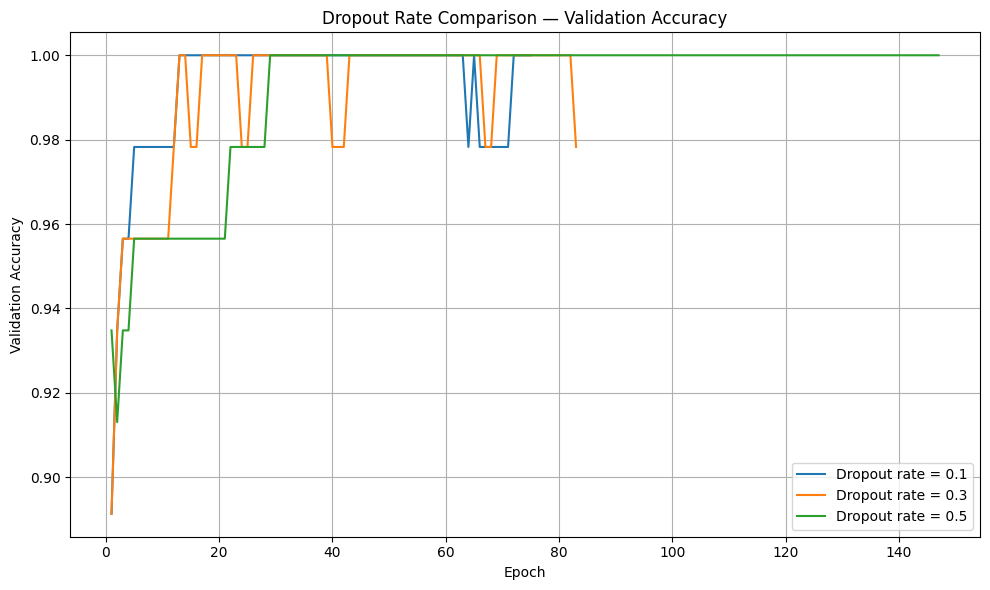


Classification Report - Dropout 0.1
              precision    recall  f1-score   support

   Malignant       0.93      0.98      0.95        42
      Benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114


Classification Report - Dropout 0.3
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Classification Report - Dropout 0.5
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg     

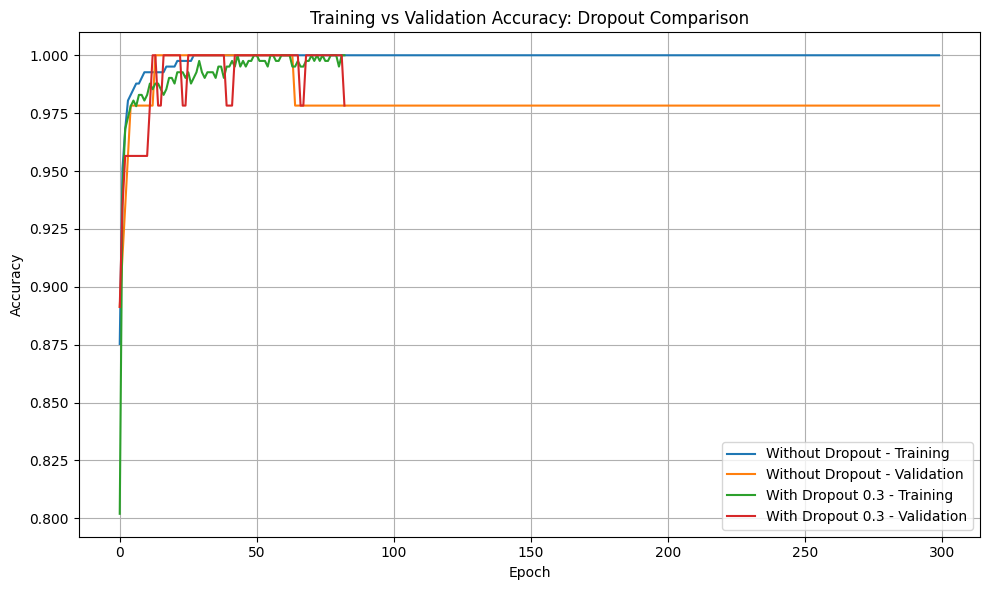


DROPOUT RATE TRADE-OFF:

Dropout 0.1:
A low dropout rate may provide insufficient regularisation,
so overfitting may remain.

Dropout 0.3:
Provides moderate regularisation and may help the model
generalise to unseen data.

Dropout 0.5:
A high dropout rate disables more activations during training.
This can slow learning or cause underfitting.

The best rate depends on validation performance.
A smaller training-validation gap can indicate less overfitting,
but it does not guarantee better test performance.

Task 5 completed successfully!



In [6]:

# ============================================================
# TASK 5: DROPOUT LAYERS
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping


# -----------------------------------------------------------
# 5.1 Build MLP with Dropout (rate = 0.3)
# ------------------------------------------------------------

def build_dropout_model(dropout_rate):
    model = keras.Sequential([
        keras.Input(shape=(30,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


model_drop = build_dropout_model(0.3)

print("Dropout Model Summary:")
model_drop.summary()

print("\nTrainable Parameters:", model_drop.count_params())


# ------------------------------------------------------------
# 5.2 WHY Dropout - Explanation
# ------------------------------------------------------------

print("""
WHY DROPOUT?

1. Dropout(rate=0.3) randomly disables 30% of activations
   during each training batch.

2. It prevents the network from depending too much on
   particular neurons.

3. It encourages the network to learn more robust features.

4. During prediction and evaluation, Dropout is disabled.

5. Dropout can reduce overfitting and improve generalisation.

6. Too much Dropout may cause underfitting.
""")


# ------------------------------------------------------------
# 5.3 Train with Dropout + Early Stopping
# ------------------------------------------------------------

es = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_drop = model_drop.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

print("\nEpochs Trained:", len(history_drop.history["loss"]))
print("Best Validation Loss:", min(history_drop.history["val_loss"]))


# ------------------------------------------------------------
# 5.4 Effect of Dropout Rate: 0.1, 0.3, 0.5
# ------------------------------------------------------------

dropout_rates = [0.1, 0.3, 0.5]
dropout_histories = {0.3: history_drop}
dropout_models = {0.3: model_drop}

for rate in [0.1, 0.5]:

    print(f"\nTraining model with Dropout rate = {rate}")

    model = build_dropout_model(rate)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train_sc,
        y_train,
        epochs=200,
        batch_size=32,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=1
    )

    dropout_models[rate] = model
    dropout_histories[rate] = history


# Plot validation accuracy for all dropout rates
plt.figure(figsize=(10, 6))

for rate in dropout_rates:
    history = dropout_histories[rate]

    plt.plot(
        range(1, len(history.history["val_accuracy"]) + 1),
        history.history["val_accuracy"],
        label=f"Dropout rate = {rate}"
    )

plt.title("Dropout Rate Comparison — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.5 Evaluate Dropout Models
# ------------------------------------------------------------

results = []

for rate in dropout_rates:

    model = dropout_models[rate]

    # Evaluate on test data
    test_loss, test_accuracy = model.evaluate(
        X_test_sc,
        y_test,
        verbose=0
    )

    # Predictions
    probabilities = model.predict(
        X_test_sc,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    # Training and validation accuracy
    history = dropout_histories[rate].history

    train_accuracy = history["accuracy"][-1]
    val_accuracy = history["val_accuracy"][-1]

    results.append({
        "Dropout Rate": rate,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train-Val Gap": abs(train_accuracy - val_accuracy)
    })

    print(f"\nClassification Report - Dropout {rate}")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))


# Display results table
results_df = pd.DataFrame(results)

print("\nDROPOUT MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))


# Select best dropout rate based on validation accuracy
best_rate = max(
    dropout_rates,
    key=lambda rate: max(
        dropout_histories[rate].history["val_accuracy"]
    )
)

best_dropout_model = dropout_models[best_rate]

print("\nBest Dropout Rate:", best_rate)


# Store best model accuracy for Task 7
best_drop_loss, best_drop_acc = best_dropout_model.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

dropout_test_accuracy = best_drop_acc

print(f"Best Dropout Test Accuracy: {dropout_test_accuracy * 100:.2f}%")


# ------------------------------------------------------------
# Compare Training and Validation Accuracy: Dropout vs No Dropout
# ------------------------------------------------------------

# Use the Task 4 model without Early Stopping, if already trained.
# If model_no_es and history_no_es exist, compare them with rate 0.3.

try:
    plt.figure(figsize=(10, 6))

    plt.plot(
        history_no_es.history["accuracy"],
        label="Without Dropout - Training"
    )

    plt.plot(
        history_no_es.history["val_accuracy"],
        label="Without Dropout - Validation"
    )

    plt.plot(
        history_drop.history["accuracy"],
        label="With Dropout 0.3 - Training"
    )

    plt.plot(
        history_drop.history["val_accuracy"],
        label="With Dropout 0.3 - Validation"
    )

    plt.title("Training vs Validation Accuracy: Dropout Comparison")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

except NameError:
    print(
        "\nRun Task 4 first to compare the model without Dropout."
    )


# ------------------------------------------------------------
# Markdown explanation
# ------------------------------------------------------------

print("""
DROPOUT RATE TRADE-OFF:

Dropout 0.1:
A low dropout rate may provide insufficient regularisation,
so overfitting may remain.

Dropout 0.3:
Provides moderate regularisation and may help the model
generalise to unseen data.

Dropout 0.5:
A high dropout rate disables more activations during training.
This can slow learning or cause underfitting.

The best rate depends on validation performance.
A smaller training-validation gap can indicate less overfitting,
but it does not guarantee better test performance.

Task 5 completed successfully!
""")


L2 Regularization Model Summary:


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7751 - loss: 0.7852 - val_accuracy: 0.9348 - val_loss: 0.5926
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9511 - loss: 0.4794 - val_accuracy: 0.9348 - val_loss: 0.4488
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9535 - loss: 0.3695 - val_accuracy: 0.9348 - val_loss: 0.3899
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.3233 - val_accuracy: 0.9565 - val_loss: 0.3502
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9804 - loss: 0.2978 - val_accuracy: 0.9783 - val_loss: 0.3199
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.2812 - val_accuracy: 0.9783 - val_loss: 0.2991
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.2677 - val_accuracy: 0.9783 - val_loss: 0.2835
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9853 - loss: 0.2556 - val_accuracy: 0.9783 -

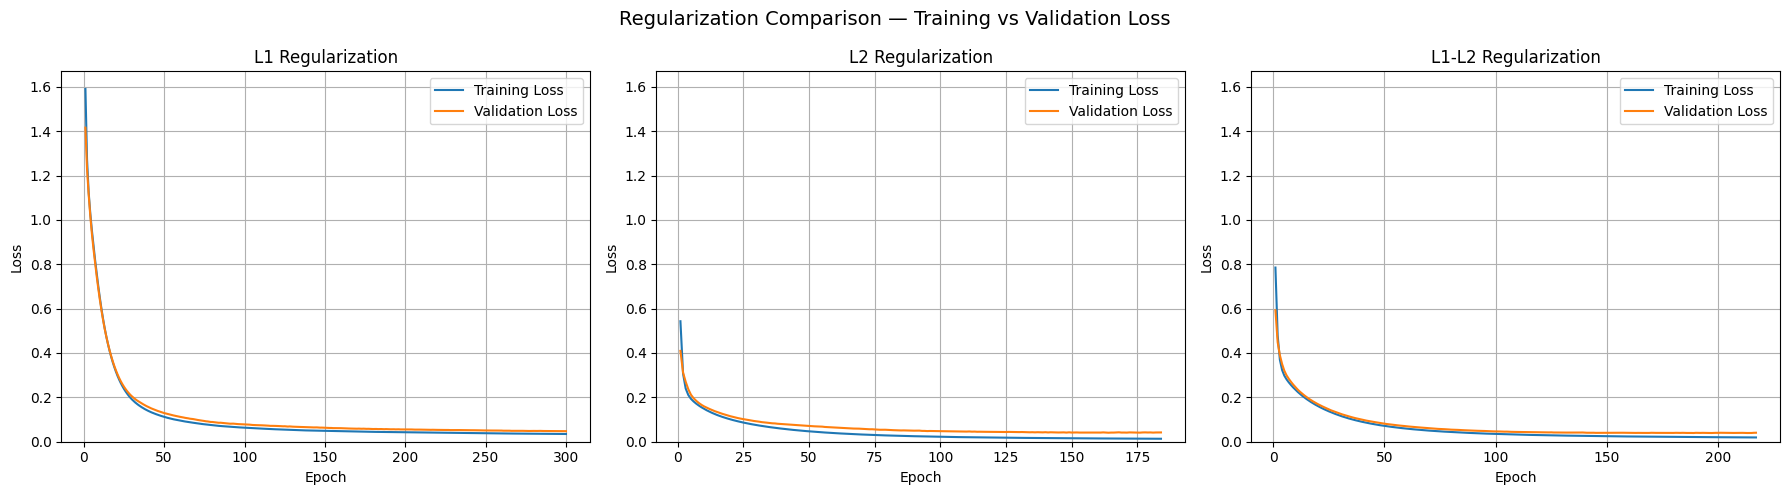


REGULARIZATION COMPARISON:

Compare the training and validation loss curves.

1. A smaller gap can indicate reduced overfitting.
2. The lowest validation loss indicates better validation
   performance during training.
3. L1 may encourage sparse weights.
4. L2 may shrink weights more smoothly.
5. L1-L2 combines both effects.

The best method cannot be determined theoretically alone.
Check the actual validation loss and test performance.


Classification Report - L1
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Classification Report - L2
              precision    recall  f1-score   support

   Malignant       0.89      0.98      0.93        42
      Benign       0.99      0.93      0.96        72

    accura

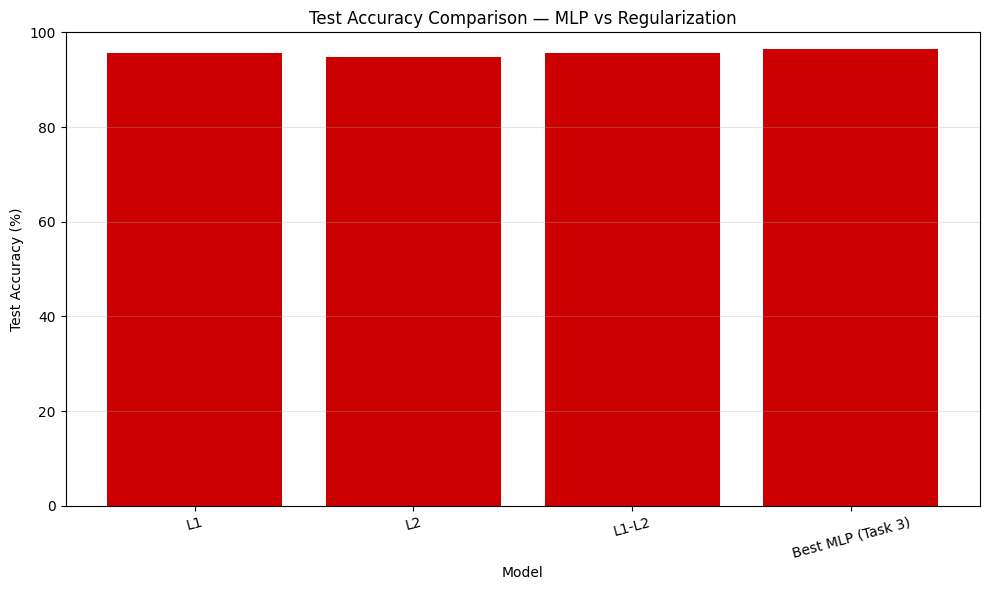


Saved results for Task 7:
L1 Accuracy:   95.61%
L2 Accuracy:   94.74%
L1-L2 Accuracy: 95.61%

Task 6 completed successfully!


In [7]:

# ============================================================
# TASK 6: REGULARIZATION (L1, L2, L1-L2 / ELASTIC NET)
# ============================================================


from tensorflow.keras import  regularizers

# ------------------------------------------------------------
# Common function to build regularized MLP
# ------------------------------------------------------------

def build_regularized_mlp(reg_type):

    if reg_type == "L2":
        reg = regularizers.l2(0.001)

    elif reg_type == "L1":
        reg = regularizers.l1(0.001)

    elif reg_type == "L1-L2":
        reg = regularizers.l1_l2(l1=0.0001, l2=0.001)

    model = keras.Sequential([
        keras.Input(shape=(30,)),
        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=reg
        ),
        layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=reg
        ),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Early Stopping callback
def get_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )


# ------------------------------------------------------------
# 6.1 Build MLP with L2 Regularization
# ------------------------------------------------------------

model_l2 = build_regularized_mlp("L2")

print("L2 Regularization Model Summary:")
model_l2.summary()

history_l2 = model_l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[get_early_stopping()],
    verbose=1
)

print("\nL2 Best Validation Loss:",
      min(history_l2.history["val_loss"]))


# ------------------------------------------------------------
# 6.2 WHY L2 Regularization - Explanation
# ------------------------------------------------------------

print("""
WHY L2 REGULARIZATION?

1. L2 adds a penalty based on the squared weights to the loss.
2. It encourages weights to remain small.
3. It can reduce overfitting and improve generalization.
4. It usually makes weights smaller but not exactly zero.
5. A very high regularization strength can cause underfitting.

Formula:
Total Loss = Binary Cross-Entropy + lambda * Sum of Squared Weights
""")


# ------------------------------------------------------------
# 6.3 Build MLP with L1 Regularization
# ------------------------------------------------------------

model_l1 = build_regularized_mlp("L1")

print("\nL1 Regularization Model Summary:")
model_l1.summary()

history_l1 = model_l1.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[get_early_stopping()],
    verbose=1
)

print("\nL1 Best Validation Loss:",
      min(history_l1.history["val_loss"]))

print("""
WHY L1 REGULARIZATION?

1. L1 adds a penalty based on the absolute values of weights.
2. It can make some weights exactly zero.
3. This can encourage sparse models and act like feature selection.
4. However, L1 does not guarantee that every irrelevant feature
   will be removed.
5. On correlated features, L1 may select some features and
   ignore others.
""")


# ------------------------------------------------------------
# 6.4 Build MLP with L1-L2 Regularization (ElasticNet)
# ------------------------------------------------------------

model_l1l2 = build_regularized_mlp("L1-L2")

print("\nL1-L2 Regularization Model Summary:")
model_l1l2.summary()

history_l1l2 = model_l1l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[get_early_stopping()],
    verbose=1
)

print("\nL1-L2 Best Validation Loss:",
      min(history_l1l2.history["val_loss"]))

print("""
WHY L1-L2 (ELASTIC NET)?

1. ElasticNet combines L1 and L2 penalties.
2. L1 encourages sparse weights.
3. L2 encourages smaller and more stable weights.
4. It can be useful when features are correlated.
5. Performance depends on the dataset and penalty strengths.
""")


# ------------------------------------------------------------
# 6.5 Regularization Comparison Plot
# ------------------------------------------------------------

histories = {
    "L1": history_l1,
    "L2": history_l2,
    "L1-L2": history_l1l2
}

# Use a common y-axis range for all three plots
all_losses = []

for history in histories.values():
    all_losses.extend(history.history["loss"])
    all_losses.extend(history.history["val_loss"])

y_max = max(all_losses) * 1.05

plt.figure(figsize=(18, 5))

for index, (name, history) in enumerate(histories.items(), start=1):

    plt.subplot(1, 3, index)

    epochs = range(1, len(history.history["loss"]) + 1)

    plt.plot(
        epochs,
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{name} Regularization")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.ylim(0, y_max)
    plt.legend()
    plt.grid(True)

plt.suptitle(
    "Regularization Comparison — Training vs Validation Loss",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Markdown-style explanation
print("""
REGULARIZATION COMPARISON:

Compare the training and validation loss curves.

1. A smaller gap can indicate reduced overfitting.
2. The lowest validation loss indicates better validation
   performance during training.
3. L1 may encourage sparse weights.
4. L2 may shrink weights more smoothly.
5. L1-L2 combines both effects.

The best method cannot be determined theoretically alone.
Check the actual validation loss and test performance.
""")


# ------------------------------------------------------------
# 6.6 Evaluate all three regularized models
# ------------------------------------------------------------

models = {
    "L1": model_l1,
    "L2": model_l2,
    "L1-L2": model_l1l2
}

results = []

for name, model in models.items():

    test_loss, test_acc = model.evaluate(
        X_test_sc,
        y_test,
        verbose=0
    )

    y_prob = model.predict(
        X_test_sc,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc
    })

    print(f"\nClassification Report - {name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))


# ------------------------------------------------------------
# Include best MLP from Task 3, if already available
# ------------------------------------------------------------

if "best_model" in globals():

    best_mlp = best_model

elif "model_mlp" in globals():

    best_mlp = model_mlp

else:

    best_mlp = None


if best_mlp is not None:

    mlp_loss, mlp_acc = best_mlp.evaluate(
        X_test_sc,
        y_test,
        verbose=0
    )

    results.append({
        "Model": "Best MLP (Task 3)",
        "Test Loss": mlp_loss,
        "Test Accuracy": mlp_acc
    })


# ------------------------------------------------------------
# Display results comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nTEST ACCURACY COMPARISON TABLE")
print(results_df.round(4).to_string(index=False))


# ------------------------------------------------------------
# Grouped bar chart of test accuracy
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"] * 100,
    color="#CC0000"
)

plt.title("Test Accuracy Comparison — MLP vs Regularization")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Save accuracies for Task 7
# ------------------------------------------------------------

l1_test_accuracy = results_df.loc[
    results_df["Model"] == "L1", "Test Accuracy"
].iloc[0]

l2_test_accuracy = results_df.loc[
    results_df["Model"] == "L2", "Test Accuracy"
].iloc[0]

l1l2_test_accuracy = results_df.loc[
    results_df["Model"] == "L1-L2", "Test Accuracy"
].iloc[0]

print("\nSaved results for Task 7:")
print(f"L1 Accuracy:   {l1_test_accuracy * 100:.2f}%")
print(f"L2 Accuracy:   {l2_test_accuracy * 100:.2f}%")
print(f"L1-L2 Accuracy: {l1l2_test_accuracy * 100:.2f}%")

print("\nTask 6 completed successfully!")


FINAL COMBINED MODEL SUMMARY


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.7946 - loss: 0.5900 - val_accuracy: 0.9348 - val_loss: 0.3740
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9560 - loss: 0.3209 - val_accuracy: 0.9565 - val_loss: 0.3010
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9682 - loss: 0.2596 - val_accuracy: 0.9348 - val_loss: 0.2682
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9682 - loss: 0.2287 - val_accuracy: 0.9783 - val_loss: 0.2402
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9853 - loss: 0.2085 - val_accuracy: 0.9783 - val_loss: 0.2201
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.2013 - val_accuracy: 0.9783 - val_loss: 0.2091
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9804 - loss: 0.1968 - val_accuracy: 0.9783 - val_loss: 0.1997
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9780 - loss: 0.1958 - val_accuracy: 0.

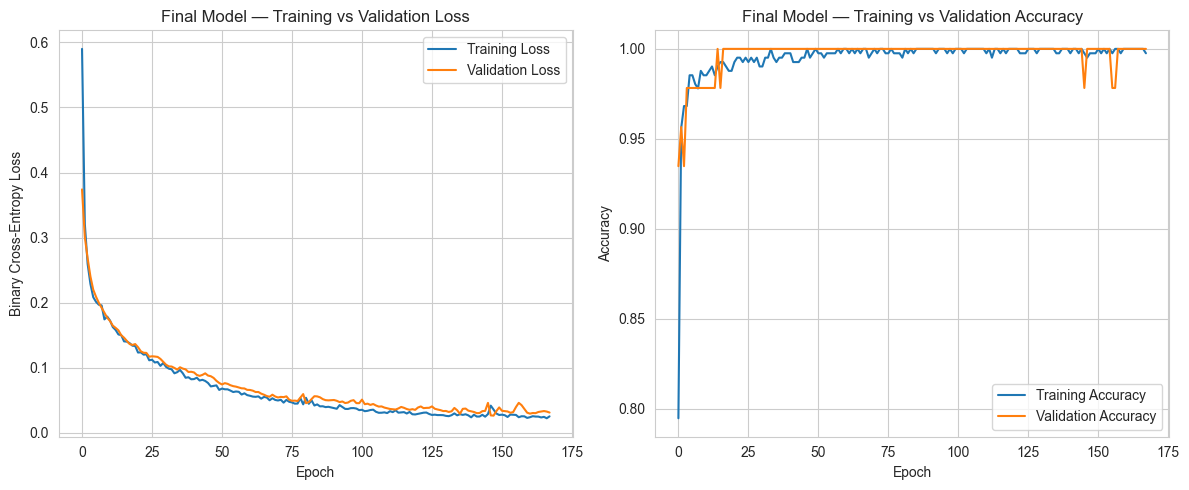


FULL MODEL RESULTS COMPARISON


,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),30 -> 1,None,0.0,No,93.86%,90.70%,92.86%,91.76%
1,MLP-ReLU (Task 3),30 -> 64 -> 32 -> 1,None,0.0,No,96.49%,93.18%,97.62%,95.35%
2,MLP + Early Stopping (Task 4),30 -> 128 -> 64 -> 1,None,0.0,Yes,95.61%,91.11%,97.62%,94.25%
3,MLP + Dropout-best (Task 5),30 -> 128 -> 64 -> 1,None,0.1,Yes,96.49%,93.18%,97.62%,95.35%
4,MLP + L2 (Task 6),30 -> 128 -> 64 -> 1,L2 (0.001),0.0,Yes,94.74%,89.13%,97.62%,93.18%
5,Final Combined Model (Task 7.1),30 -> 128 -> 64 -> 1,L2 (0.001),0.3,Yes,95.61%,91.11%,97.62%,94.25%



Results saved to model_results_comparison.csv


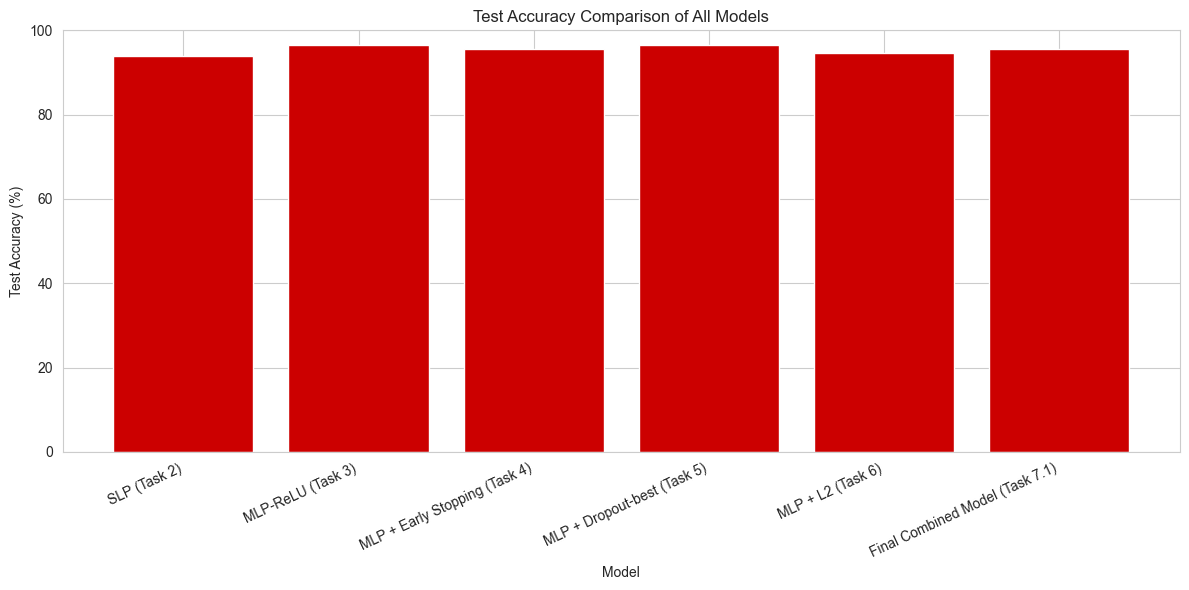


FINAL MODEL TEST RESULTS
------------------------
Test Loss: 0.1682
Test Accuracy: 95.61%

Classification Report (Malignant = Positive Class):
              precision    recall  f1-score   support

      Benign       0.99      0.94      0.96        72
   Malignant       0.91      0.98      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



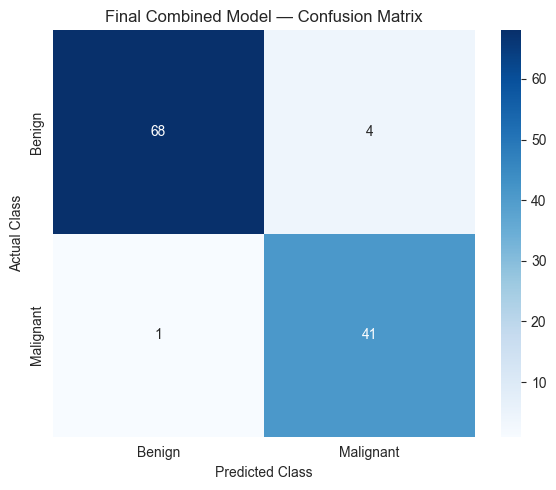


CLINICAL INSIGHT FOR MEDICAL DIAGNOSIS SUPPORT

1. Model Recommendation
----------------------
The final combined model uses L2 regularization, Dropout,
and Early Stopping. These techniques can help reduce
overfitting. However, it should only be considered a candidate
for further validation, not automatically approved for clinical
deployment.

2. Precision vs Recall
----------------------
A false negative means a malignant case is classified as benign.
This can be dangerous in cancer screening.

Recall for the malignant class is therefore particularly
important. Precision must also be monitored because false
positives can cause unnecessary follow-up tests and anxiety.

3. Classification Threshold
----------------------------
The model outputs the probability of class 1 (Benign).

Default threshold:
- Probability of Benign >= 0.50: predict Benign.
- Probability of Benign < 0.50: predict Malignant.

A lower threshold for predicting Benign, such as 0.30,
will classify more cases as Malig

In [8]:

# ============================================================
# TASK 7: FINAL MODEL + FULL RESULTS + CLINICAL INSIGHTS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Notebook plotting style
sns.set_style("whitegrid")

# ------------------------------------------------------------
# 7.1 Build Final Combined Model
# L2 + Dropout + Early Stopping
# ------------------------------------------------------------

model_final = keras.Sequential([
    keras.Input(shape=(30,)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.3),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("FINAL COMBINED MODEL SUMMARY")
model_final.summary()

# Train final model with Early Stopping
es_final = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_final = model_final.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_final],
    verbose=1
)

print("\nBest Validation Loss:",
      min(history_final.history["val_loss"]))


# Plot final model training curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_final.history["loss"], label="Training Loss")
plt.plot(history_final.history["val_loss"], label="Validation Loss")
plt.title("Final Model — Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_final.history["accuracy"], label="Training Accuracy")
plt.plot(history_final.history["val_accuracy"], label="Validation Accuracy")
plt.title("Final Model — Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7.2 Full Results Comparison Table
# ------------------------------------------------------------

# Models created in Tasks 2–6
# Run those tasks before running this section.

model_records = [
    {
        "Model": "SLP (Task 2)",
        "Architecture": "30 -> 1",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No",
        "Estimator": model_slp
    },
    {
        "Model": "MLP-ReLU (Task 3)",
        "Architecture": "30 -> 64 -> 32 -> 1",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No",
        "Estimator": model_mlp
    },
    {
        "Model": "MLP + Early Stopping (Task 4)",
        "Architecture": "30 -> 128 -> 64 -> 1",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes",
        "Estimator": model_es
    },
    {
        "Model": "MLP + Dropout-best (Task 5)",
        "Architecture": "30 -> 128 -> 64 -> 1",
        "Regularization": "None",
        "Dropout Rate": best_rate,
        "Early Stopping": "Yes",
        "Estimator": best_dropout_model
    },
    {
        "Model": "MLP + L2 (Task 6)",
        "Architecture": "30 -> 128 -> 64 -> 1",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes",
        "Estimator": model_l2
    },
    {
        "Model": "Final Combined Model (Task 7.1)",
        "Architecture": "30 -> 128 -> 64 -> 1",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.3,
        "Early Stopping": "Yes",
        "Estimator": model_final
    }
]


# IMPORTANT:
# Dataset labels: 0 = Malignant, 1 = Benign.
# For clinical interpretation, define MALIGNANT as the positive
# class when calculating precision, recall and F1-score.

y_true = np.asarray(y_test).astype(int)
y_true_malignant = (y_true == 0).astype(int)

results = []

for record in model_records:

    estimator = record["Estimator"]

    # Model outputs probability of class 1 (Benign)
    prob_benign = estimator.predict(
        X_test_sc,
        verbose=0
    ).ravel()

    # Default threshold = 0.5
    pred_class = (prob_benign >= 0.5).astype(int)

    # Convert predictions so malignant = positive class
    pred_malignant = (pred_class == 0).astype(int)

    results.append({
        "Model": record["Model"],
        "Architecture": record["Architecture"],
        "Regularization": record["Regularization"],
        "Dropout Rate": record["Dropout Rate"],
        "Early Stopping": record["Early Stopping"],
        "Test Accuracy": accuracy_score(y_true, pred_class),
        "Test Precision": precision_score(
            y_true_malignant, pred_malignant, zero_division=0
        ),
        "Test Recall": recall_score(
            y_true_malignant, pred_malignant, zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_true_malignant, pred_malignant, zero_division=0
        )
    })


df_results = pd.DataFrame(results)

print("\nFULL MODEL RESULTS COMPARISON")
display(
    df_results.style
    .format({
        "Test Accuracy": "{:.2%}",
        "Test Precision": "{:.2%}",
        "Test Recall": "{:.2%}",
        "Test F1-Score": "{:.2%}",
        "Dropout Rate": "{:.1f}"
    })
    .highlight_max(
        subset=["Test Accuracy", "Test F1-Score"],
        color="#ffcccc"
    )
)

# Save results for your project report
df_results.to_csv("model_results_comparison.csv", index=False)
print("\nResults saved to model_results_comparison.csv")


# ------------------------------------------------------------
# 7.3 Compare Test Accuracy of All Models
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    df_results["Model"],
    df_results["Test Accuracy"] * 100,
    color="#CC0000"
)

plt.title("Test Accuracy Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7.4 Evaluate Final Model in Detail
# ------------------------------------------------------------

final_loss, final_accuracy = model_final.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

final_prob_benign = model_final.predict(
    X_test_sc,
    verbose=0
).ravel()

final_pred = (final_prob_benign >= 0.5).astype(int)
final_pred_malignant = (final_pred == 0).astype(int)

print("\nFINAL MODEL TEST RESULTS")
print("------------------------")
print(f"Test Loss: {final_loss:.4f}")
print(f"Test Accuracy: {final_accuracy:.2%}")

print("\nClassification Report (Malignant = Positive Class):")
print(classification_report(
    y_true_malignant,
    final_pred_malignant,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

cm_final = confusion_matrix(
    y_true_malignant,
    final_pred_malignant,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Final Combined Model — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7.5 Clinical Insight for Medical Diagnosis Support
# ------------------------------------------------------------

print("""
CLINICAL INSIGHT FOR MEDICAL DIAGNOSIS SUPPORT
==============================================

1. Model Recommendation
----------------------
The final combined model uses L2 regularization, Dropout,
and Early Stopping. These techniques can help reduce
overfitting. However, it should only be considered a candidate
for further validation, not automatically approved for clinical
deployment.

2. Precision vs Recall
----------------------
A false negative means a malignant case is classified as benign.
This can be dangerous in cancer screening.

Recall for the malignant class is therefore particularly
important. Precision must also be monitored because false
positives can cause unnecessary follow-up tests and anxiety.

3. Classification Threshold
----------------------------
The model outputs the probability of class 1 (Benign).

Default threshold:
- Probability of Benign >= 0.50: predict Benign.
- Probability of Benign < 0.50: predict Malignant.

A lower threshold for predicting Benign, such as 0.30,
will classify more cases as Malignant and may increase
malignant recall, but can also increase false positives.

The threshold should be selected using validation data,
not the test set, based on clinically agreed sensitivity
and specificity requirements.

4. Generalisation Techniques
----------------------------
Compare validation loss and malignant recall across Tasks 3–6.
Early Stopping, Dropout, and L2 regularization may each help,
but the largest benefit must be determined from actual results.
Do not assume one technique is always best.

5. Safety
---------
This dataset experiment is educational. Clinical use requires
independent external validation, calibration, bias assessment,
clinical oversight, and regulatory review where applicable.
""")


# ------------------------------------------------------------
# Save final model
# ------------------------------------------------------------

model_final.save("final_breast_cancer_model.keras")

print("\nFinal model saved as final_breast_cancer_model.keras")
print("Task 7 completed successfully!")
